# Analysis of newly engineered Cardisoft features

This notebook implements and evaluates **eight proposed features**: three ratios,
two counts and three log-transformed lab values. These features are analysis
candidates; they have not been incorporated into serving models.

The analysis answers four questions:
1. Are the calculations valid, and how are their values distributed?
2. How redundant are they with existing inputs?
3. How do their distributions differ by CAD/LAD/LCX/RCA labels?
4. Do fixed feature sets change cross-validated predictions compared with the
   same model using the original 54 predictors?

The raw CSV and the existing statistical-analysis notebook are preserved. Tables,
plots, eight engineered columns and reproducibility metadata are written to
`dataset/engineered_feature_analysis/`. The reusable calculations are in
`dataset/engineered_features_analysis.py`.

## 1. Analysis protocol and boundaries

- Keep `Cath`, `LAD`, `LCX`, `RCA` and all their derivatives out of model inputs.
- Recreate the repository's **per-target stratified 80/20 split, seed 42**.
  Each target has 242 development records and 61 excluded historical-holdout
  records. Split membership differs across targets because stratification differs.
- Distribution/correlation plots use the **CAD development partition**. Each
  target-association analysis and model comparison uses that target's own
  development partition. The full-row engineered CSV is a deterministic export,
  not a fitted or selected training dataset.
- Compare six fixed feature sets with **three repeats of five-fold stratified
  CV (seeds 42, 43, 44)**. Fit imputation, scaling and encoding only on each fold's
  training rows. Use the same folds and estimator seed for every feature set.
- Freeze the deployed model families/settings: CAD uses 400-iteration native
  CatBoost; vessels use 400-tree Random Forests. There is no model search,
  calibration, early stopping, learned threshold or feature selection in this
  experiment. These are freshly trained baselines, not predictions from saved
  models that already saw development patients.
- Compare unweighted log loss, ROC-AUC, average precision, Brier score, sensitivity
  and specificity. The last two use threshold 0.5. Report **complete-repeat OOF
  metrics**; their means differ from means of fold metrics. Three repeats reuse
  the same patients and do not provide three independent samples.

These are **exploratory development comparisons**, not independent validation of
a selected winner. Further feature selection belongs inside nested CV. The cohort
has already informed earlier modeling decisions; the old holdout is not new
external validation. There is no verified patient identifier or acquisition timing,
so patient independence and pre-decision feature availability remain unverified.

Method references: [scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
and [nested CV](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

# Run from the repository root or from dataset/.
dataset_dir = next(p for p in [Path.cwd(), Path.cwd() / "dataset"]
                   if (p / "engineered_features_analysis.py").exists())
sys.path.insert(0, str(dataset_dir.resolve()))
import engineered_features_analysis as fe

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.precision", 4)
df = fe.load_data()
partitions = fe.development_partitions(df)
provenance = fe.save_provenance(df)
display(pd.DataFrame([{
    "raw_records": len(df), "raw_columns": df.shape[1],
    "original_model_inputs": len(fe.ALL_INPUT_FEATURES),
    "engineered_features": len(fe.ENGINEERED),
    "missing_raw_cells": int(df.isna().sum().sum()),
    "duplicate_input_rows": int(df.duplicated(subset=fe.ALL_INPUT_FEATURES).sum()),
    "constant_columns": ", ".join(df.columns[df.nunique(dropna=False).eq(1)]),
}]))
display(pd.DataFrame([{"target": t.upper(), "development": len(dev),
                       "excluded_holdout": len(held)}
                      for t, (dev, held) in partitions.items()]))

,raw_records,raw_columns,original_model_inputs,engineered_features,missing_raw_cells,duplicate_input_rows,constant_columns
0,303,59,54,8,0,0,Exertional CP


,target,development,excluded_holdout
0,CAD,242,61
1,LAD,242,61
2,LCX,242,61
3,RCA,242,61


## 2. Feature definitions and calculation checks

Counts use the exact constituents below. `risk_factor_count` does not include
ex-smoker status, and `ecg_finding_count` does not include LVH, BBB or poor R-wave
progression. Equal weighting is an experimental representation, not a clinical
risk scale. Ratios use the dataset's recorded units; the neutrophil and lymphocyte
columns are both percentages.

Missing or invalid constituents propagate to missing derived values. Ratio
denominators must be positive; labs used in logs must be nonnegative. Missing
counts are never silently filled with zero. There is no total cholesterol column,
so **non-HDL cholesterol is not calculated**. No undocumented severity ordering is
assigned to `Region RWMA`.

In [2]:
display(fe.feature_definitions())
raw, derived, summary, skew, correlations, raw_correlations = fe.describe_features(df, partitions)

# Correctness checks against independent formulas and edge cases.
assert np.allclose(derived.LDL_HDL_ratio, raw.LDL / raw.HDL)
assert np.allclose(derived.TG_HDL_ratio, raw.TG / raw.HDL)
assert np.allclose(derived.Neut_Lymph_ratio, raw.Neut / raw.Lymph)
assert np.array_equal(derived.risk_factor_count,
    raw[["DM", "HTN", "Current Smoker", "FH"]].sum(axis=1) + raw.DLP.eq("Y").astype(int))
assert np.array_equal(derived.ecg_finding_count,
    raw[["Q Wave", "St Elevation", "St Depression", "Tinversion"]].sum(axis=1))
for source, feature in zip(fe.LOG_SOURCES, fe.LOGS):
    assert np.allclose(np.expm1(derived[feature]), raw[source])
assert derived.risk_factor_count.between(0, 5).all()
assert derived.ecg_finding_count.between(0, 4).all()
assert np.isfinite(derived.to_numpy()).all()

edge = raw.head(3).copy()
edge.loc[edge.index[0], ["HDL", "Lymph"]] = 0
edge.loc[edge.index[1], ["DLP", "Q Wave"]] = np.nan
edge.loc[edge.index[2], "TG"] = -1
edge_features = fe.engineer_features(edge)
assert edge_features.loc[edge.index[0], fe.RATIOS].isna().all()
assert edge_features.loc[edge.index[1], fe.COUNTS].isna().all()
assert pd.isna(edge_features.loc[edge.index[2], "log1p_TG"])
assert not np.isinf(edge_features.to_numpy()).any()

# Targets cannot affect any derived value or enter any model feature set.
scrambled = df.copy()
for name in fe.LEAKAGE_COLUMNS:
    scrambled[name] = "deliberately_changed_label"
pd.testing.assert_frame_equal(fe.engineer_features(df), fe.engineer_features(scrambled))
for variant in fe.VARIANTS:
    transformed = fe.FeatureSet(variant).fit_transform(df)
    assert not set(transformed.columns) & set(fe.LEAKAGE_COLUMNS)
print("Passed: formulas, bounds, missing/zero/negative handling, and target exclusion.")

Passed: formulas, bounds, missing/zero/negative handling, and target exclusion.


,feature,formula,source_columns,type,interpretation
0,LDL_HDL_ratio,LDL / HDL,LDL; HDL,ratio,Relative lipid levels
1,TG_HDL_ratio,TG / HDL,TG; HDL,ratio,Relative lipid levels
2,Neut_Lymph_ratio,Neut / Lymph,Neut; Lymph,ratio,White-cell differential balance
3,risk_factor_count,DM + HTN + Current Smoker + FH + 1[DLP == Y],DM; HTN; Current Smoker; FH; DLP,count 0–5,Unweighted count; not a validated clinical score
4,ecg_finding_count,Q Wave + St Elevation + St Depression + Tinversion,Q Wave; St Elevation; St Depression; Tinversion,count 0–4,Four recorded ECG findings; not interchangeable diagnoses
5,log1p_TG,ln(1 + TG),TG,log transform,Compresses the right tail; adds no new measurement
6,log1p_FBS,ln(1 + FBS),FBS,log transform,Compresses the right tail; adds no new measurement
7,log1p_ESR,ln(1 + ESR),ESR,log transform,Compresses the right tail; adds no new measurement


## 3. Distributions, skewness and redundancy

The following tables describe the 242 CAD-development records. Spearman
correlations measure rank redundancy, not causal relationships. A log transform
preserves ordering, so its Spearman correlation with the original lab is 1 and
its univariate rank-based AUC is unchanged. It can still affect a model's fitted
representation, numerical behavior or regularization.

In [3]:
display(summary.round(3))
display(skew.round(3))
display(raw_correlations[raw_correlations["rank"].eq(1)].round(3))
count_frequencies = pd.concat([
    derived[name].value_counts().sort_index().rename("records").rename_axis("count")
        .reset_index().assign(feature=name)
    for name in fe.COUNTS], ignore_index=True)
count_frequencies.to_csv(fe.OUTPUT / "count_frequencies.csv", index=False)
display(count_frequencies[["feature", "count", "records"]])

redundancy = pd.DataFrame([
    {"check": "BMI max absolute difference from Weight / (Length/100)^2",
     "value": (raw.BMI - raw.Weight / (raw.Length / 100)**2).abs().max()},
    {"check": "Lymph vs Neut Pearson correlation", "value": raw.Lymph.corr(raw.Neut)},
    {"check": "CHF positive records", "value": raw.CHF.eq("Y").sum()},
    {"check": "LowTH Ang positive records", "value": raw["LowTH Ang"].eq("Y").sum()},
])
redundancy.to_csv(fe.OUTPUT / "existing_input_redundancy.csv", index=False)
display(redundancy)

,count,mean,std,min,25%,50%,75%,max,missing,unique,skew
feature,,,,,,,,,,,
LDL_HDL_ratio,242.0,2.696,1.012,0.577,1.980,2.598,3.218,6.226,0,205,1.054
TG_HDL_ratio,242.0,3.932,2.705,0.500,2.228,3.137,4.608,23.864,0,220,2.818
Neut_Lymph_ratio,242.0,2.264,1.480,0.582,1.393,1.877,2.538,12.143,0,165,3.112
risk_factor_count,242.0,1.612,1.009,0.000,1.000,2.000,2.000,4.000,0,5,0.229
ecg_finding_count,242.0,0.591,0.785,0.000,0.000,0.000,1.000,3.000,0,4,0.967
log1p_TG,242.0,4.875,0.490,3.638,4.511,4.775,5.163,6.957,0,134,0.725
log1p_FBS,242.0,4.730,0.343,4.143,4.503,4.610,4.875,5.994,0,99,1.259
log1p_ESR,242.0,2.723,0.783,0.693,2.303,2.773,3.219,4.511,0,54,-0.250


,raw_skew,log_skew
source,,
TG,4.001,0.725
FBS,2.258,1.259
ESR,1.756,-0.250


,feature,rank,raw_feature,spearman_rho
0,LDL_HDL_ratio,1,LDL,0.757
3,TG_HDL_ratio,1,TG,0.874
6,Neut_Lymph_ratio,1,Lymph,-0.987
9,risk_factor_count,1,DM,0.588
12,ecg_finding_count,1,Tinversion,0.784
15,log1p_TG,1,TG,1.000
18,log1p_FBS,1,FBS,1.000
21,log1p_ESR,1,ESR,1.000


,feature,count,records
0,risk_factor_count,0.0,31
1,risk_factor_count,1.0,89
2,risk_factor_count,2.0,71
3,risk_factor_count,3.0,45
4,risk_factor_count,4.0,6
5,ecg_finding_count,0.0,142
6,ecg_finding_count,1.0,59
7,ecg_finding_count,2.0,39
8,ecg_finding_count,3.0,2


,check,value
0,BMI max absolute difference from Weight / (Length/100)^2,4.9540e-09
1,Lymph vs Neut Pearson correlation,-9.1662e-01
2,CHF positive records,1.0000e+00
3,LowTH Ang positive records,1.0000e+00


## 4. Association with each target

Compare positive and negative class medians/IQRs using a two-sided, asymptotic
Mann–Whitney U test with tie correction. Apply Benjamini–Hochberg adjustment across
all **32 feature–target tests** as one exploratory family. Related features/tests
are dependent; adjusted values are screening summaries, not independent clinical
evidence. The cohort and candidate features were not prospectively specified.

`feature_auc` treats the raw feature value as the prediction score; no model is
fitted. `rank_biserial = 2 × feature_auc − 1`: positive means larger values tend
to occur in positive cases. AUC below 0.5 indicates an inverse relationship.
These unadjusted associations do not establish incremental predictive value
beyond the original inputs, which is examined in the next section.

References: [SciPy Mann–Whitney U](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)
and [false-discovery adjustment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html).

In [4]:
associations = fe.target_associations(df, partitions)
display(associations[["target", "feature", "positive_median", "negative_median",
                      "feature_auc", "rank_biserial", "q_value_bh_32_tests"]].round(4))
display(associations.pivot(index="feature", columns="target", values="feature_auc")
        .reindex(fe.ENGINEERED).round(3))

,target,feature,positive_median,negative_median,feature_auc,rank_biserial,q_value_bh_32_tests
0,cad,LDL_HDL_ratio,2.5385,2.6667,0.4704,-0.0591,0.5224
1,cad,TG_HDL_ratio,3.2955,2.7273,0.5816,0.1633,0.1015
2,cad,Neut_Lymph_ratio,1.9688,1.7419,0.5758,0.1515,0.1111
3,cad,risk_factor_count,2.0000,1.0000,0.6735,0.3471,0.0002
4,cad,ecg_finding_count,0.0000,0.0000,0.6506,0.3012,0.0003
5,cad,log1p_TG,4.8598,4.7095,0.6110,0.2220,0.0226
6,cad,log1p_FBS,4.6634,4.5326,0.6854,0.3709,0.0002
7,cad,log1p_ESR,2.8332,2.5649,0.6443,0.2886,0.0023
8,lad,LDL_HDL_ratio,2.5750,2.6216,0.5131,0.0262,0.7291
9,lad,TG_HDL_ratio,3.3333,3.1351,0.5551,0.1102,0.2008


target,cad,lad,lcx,rca
feature,,,,
LDL_HDL_ratio,0.470,0.513,0.521,0.522
TG_HDL_ratio,0.582,0.555,0.545,0.540
Neut_Lymph_ratio,0.576,0.612,0.536,0.650
risk_factor_count,0.674,0.591,0.583,0.628
ecg_finding_count,0.651,0.641,0.551,0.530
log1p_TG,0.611,0.570,0.570,0.557
log1p_FBS,0.685,0.584,0.547,0.571
log1p_ESR,0.644,0.624,0.561,0.600


## 5. Controlled feature-set comparison

| Feature set | Change from the original 54 inputs |
|---|---|
| baseline | No derived features |
| ratios | Add all three ratios |
| counts | Add both counts |
| logs | Replace TG, FBS and ESR with their log1p transforms |
| ratios_counts | Add all three ratios and both counts |
| ratios_counts_logs | Add ratios/counts and replace the three labs with logs |

Keep the original component inputs for ratios and counts. No feature is selected
from its univariate p-value. This group comparison does not isolate the incremental
contribution of an individual ratio or count. All six alternatives are fixed
before running CV. Repeated CV evaluates 360 fresh fits (4 targets × 3 seeds ×
5 folds × 6 feature sets). Running this cell takes several minutes.

**Negative changes in log loss/Brier are improvements; positive changes in
ROC-AUC/AP are improvements.** Sensitivity and specificity can trade off at the
fixed threshold. AP's no-skill reference depends on each target's prevalence.

In [5]:
fold_metrics, oof_predictions, repeat_metrics, cv_summary, paired_deltas = fe.benchmark(df, partitions)
display(cv_summary[["target", "variant", "roc_auc_mean", "roc_auc_std",
                    "log_loss_mean", "log_loss_std", "brier_mean",
                    "average_precision_mean", "sensitivity_mean", "specificity_mean"]].round(4))

Completed 5/60 fold groups (30 fits)
Completed 10/60 fold groups (60 fits)
Completed 15/60 fold groups (90 fits)
Completed 20/60 fold groups (120 fits)
Completed 25/60 fold groups (150 fits)
Completed 30/60 fold groups (180 fits)
Completed 35/60 fold groups (210 fits)
Completed 40/60 fold groups (240 fits)
Completed 45/60 fold groups (270 fits)
Completed 50/60 fold groups (300 fits)
Completed 55/60 fold groups (330 fits)
Completed 60/60 fold groups (360 fits)


,target,variant,roc_auc_mean,roc_auc_std,log_loss_mean,log_loss_std,brier_mean,average_precision_mean,sensitivity_mean,specificity_mean
0,cad,baseline,0.9284,0.0112,0.3337,0.0308,0.0989,0.9712,0.8998,0.7729
1,cad,counts,0.9296,0.0115,0.3256,0.0270,0.0963,0.9709,0.9075,0.7826
2,cad,logs,0.9296,0.0072,0.3286,0.0193,0.0972,0.9716,0.9094,0.7923
3,cad,ratios,0.9285,0.0048,0.3273,0.0112,0.0978,0.9708,0.9037,0.7778
4,cad,ratios_counts,0.9289,0.0108,0.3265,0.0299,0.0980,0.9709,0.9114,0.7729
5,cad,ratios_counts_logs,0.9294,0.0081,0.3313,0.0197,0.0991,0.9717,0.9056,0.7826
6,lad,baseline,0.8391,0.0112,0.5196,0.0081,0.1702,0.8745,0.8676,0.6436
7,lad,counts,0.8417,0.0119,0.5141,0.0102,0.1679,0.8739,0.8794,0.6469
8,lad,logs,0.8365,0.0059,0.5199,0.0047,0.1705,0.8727,0.8676,0.6403
9,lad,ratios,0.8394,0.0063,0.5193,0.0060,0.1702,0.8781,0.8676,0.6403


In [6]:
delta_columns = ["delta_roc_auc", "delta_log_loss", "delta_brier", "delta_average_precision"]
paired_summary = paired_deltas.groupby(["target", "variant"])[delta_columns].agg(["mean", "std"])
paired_summary.columns = ["_".join(c) for c in paired_summary.columns]
paired_summary = paired_summary.reset_index()
paired_summary.to_csv(fe.OUTPUT / "cv_paired_summary.csv", index=False)
display(paired_summary.round(4))

# Every patient gets exactly one OOF prediction per target/seed/feature set.
assert not oof_predictions.duplicated(["target", "seed", "variant", "row_index"]).any()
assert len(oof_predictions) == 4 * 3 * 6 * 242
for target, (dev, held) in partitions.items():
    seen = set(oof_predictions.loc[oof_predictions.target.eq(target), "row_index"])
    assert seen == set(dev) and not seen & set(held)
print("Verified all 17,424 OOF predictions; no target's excluded holdout was scored.")

Verified all 17,424 OOF predictions; no target's excluded holdout was scored.


,target,variant,delta_roc_auc_mean,delta_roc_auc_std,delta_log_loss_mean,delta_log_loss_std,delta_brier_mean,delta_brier_std,delta_average_precision_mean,delta_average_precision_std
0,cad,baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,cad,counts,0.0011,0.0073,-0.0081,0.0099,-0.0027,0.0038,-0.0003,0.0042
2,cad,logs,0.0012,0.0073,-0.0051,0.0180,-0.0017,0.0066,0.0005,0.0032
3,cad,ratios,0.0001,0.0074,-0.0064,0.0197,-0.0012,0.0064,-0.0004,0.0034
4,cad,ratios_counts,0.0005,0.0052,-0.0072,0.0071,-0.0009,0.0023,-0.0003,0.0027
5,cad,ratios_counts_logs,0.0009,0.0103,-0.0024,0.0259,0.0002,0.0093,0.0005,0.0042
6,lad,baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,lad,counts,0.0026,0.0044,-0.0054,0.0034,-0.0023,0.0016,-0.0006,0.0035
8,lad,logs,-0.0027,0.0053,0.0003,0.0034,0.0003,0.0017,-0.0018,0.0031
9,lad,ratios,0.0002,0.0049,-0.0003,0.0024,-0.0000,0.0011,0.0036,0.0049


## 6. Visual analysis

Plots below are also saved as standalone PNG files. The paired CV plot shows
individual complete-repeat differences, rather than an uncertainty interval that
would incorrectly treat correlated folds or repeated patients as independent.

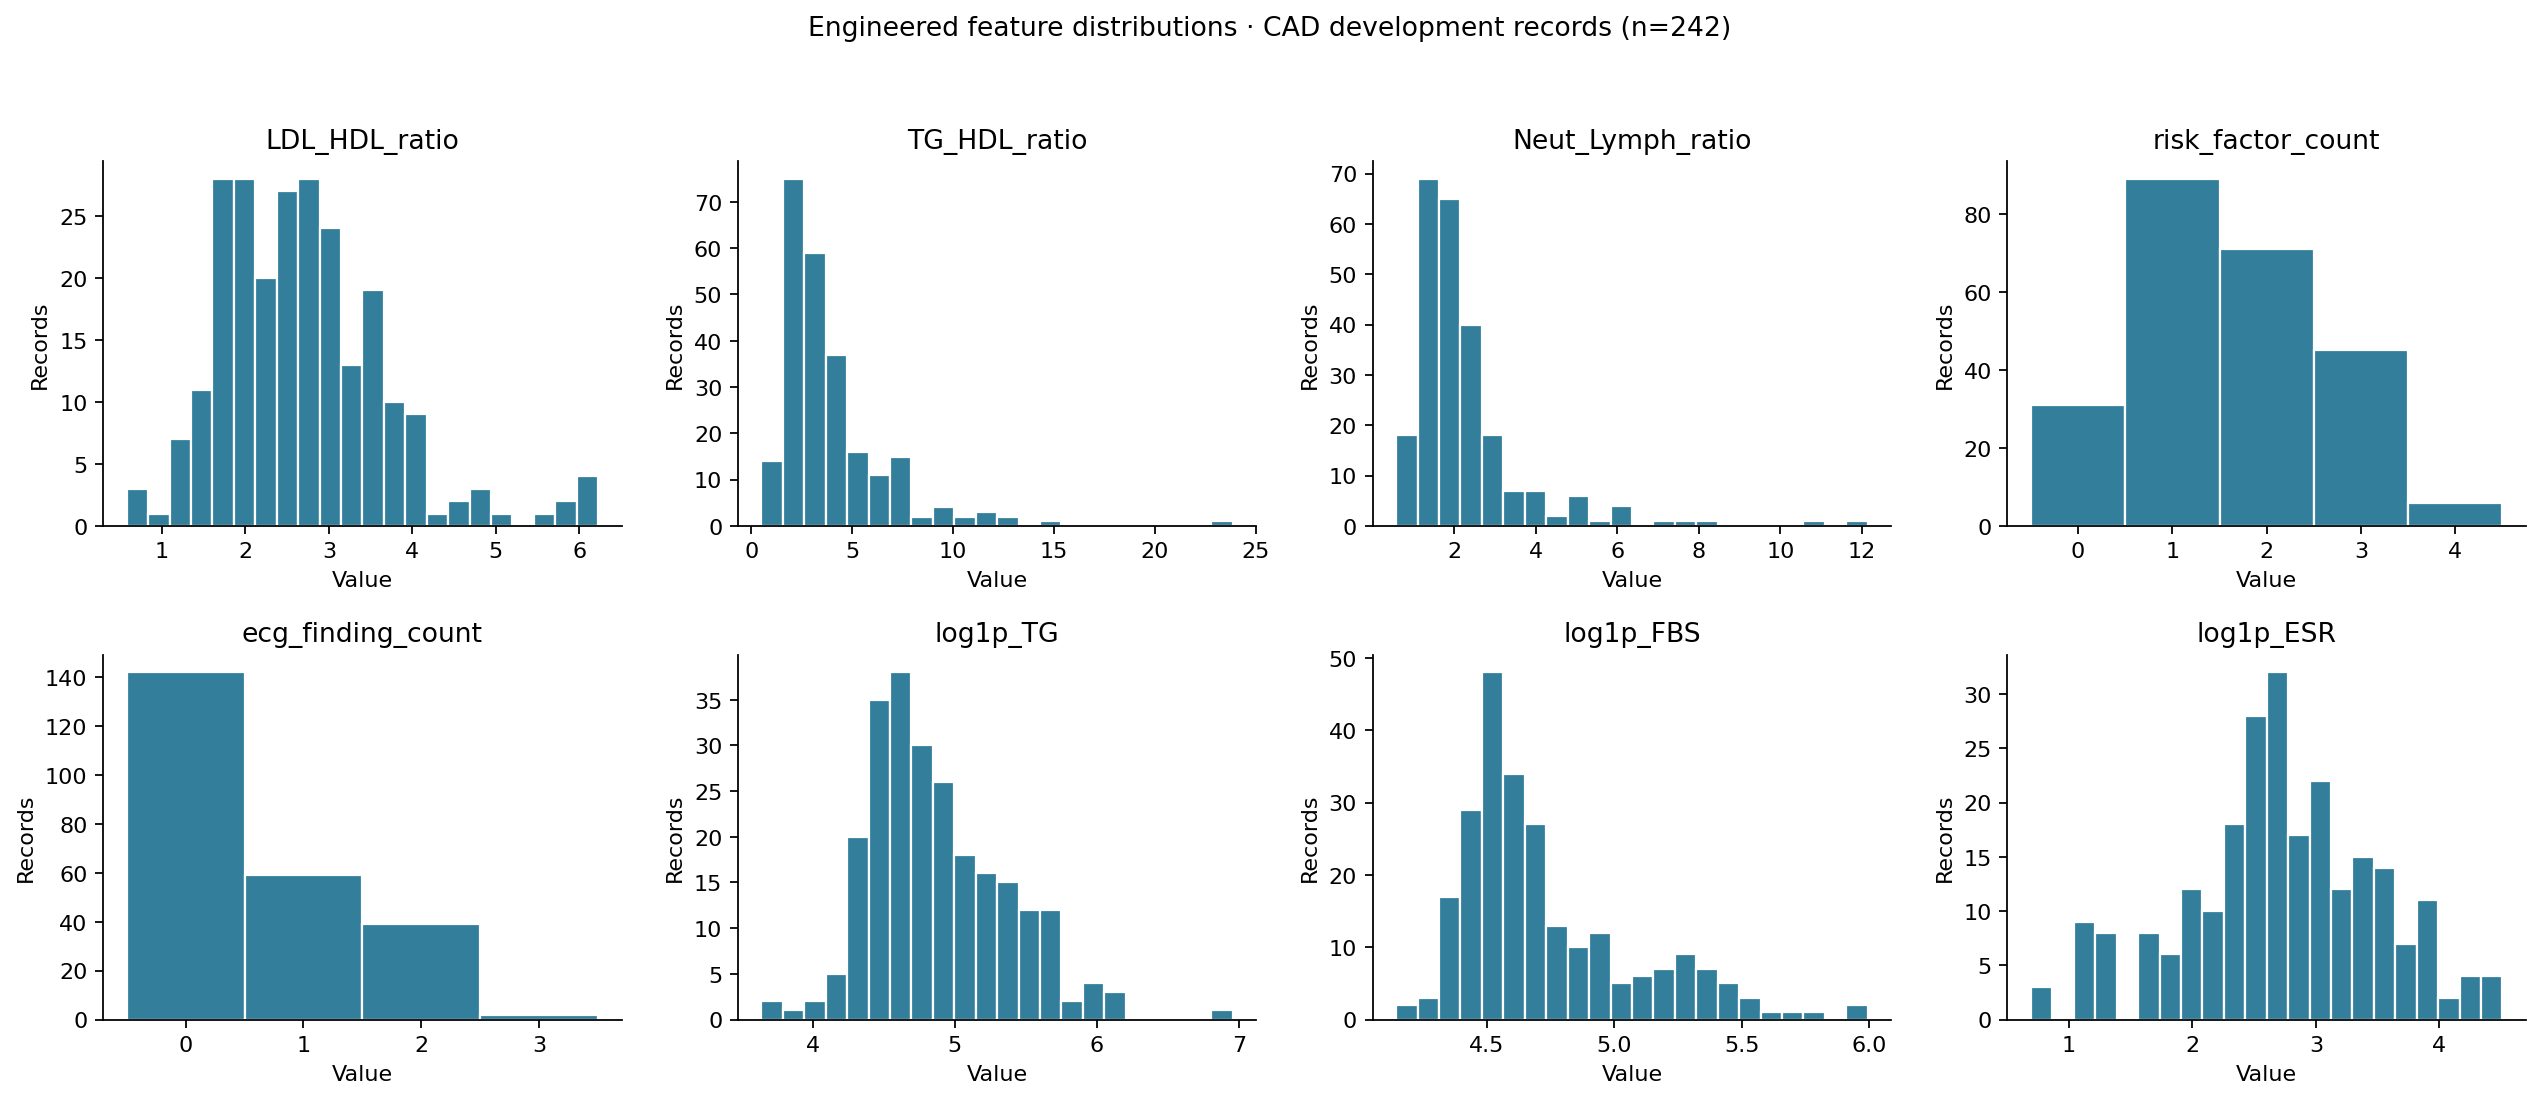

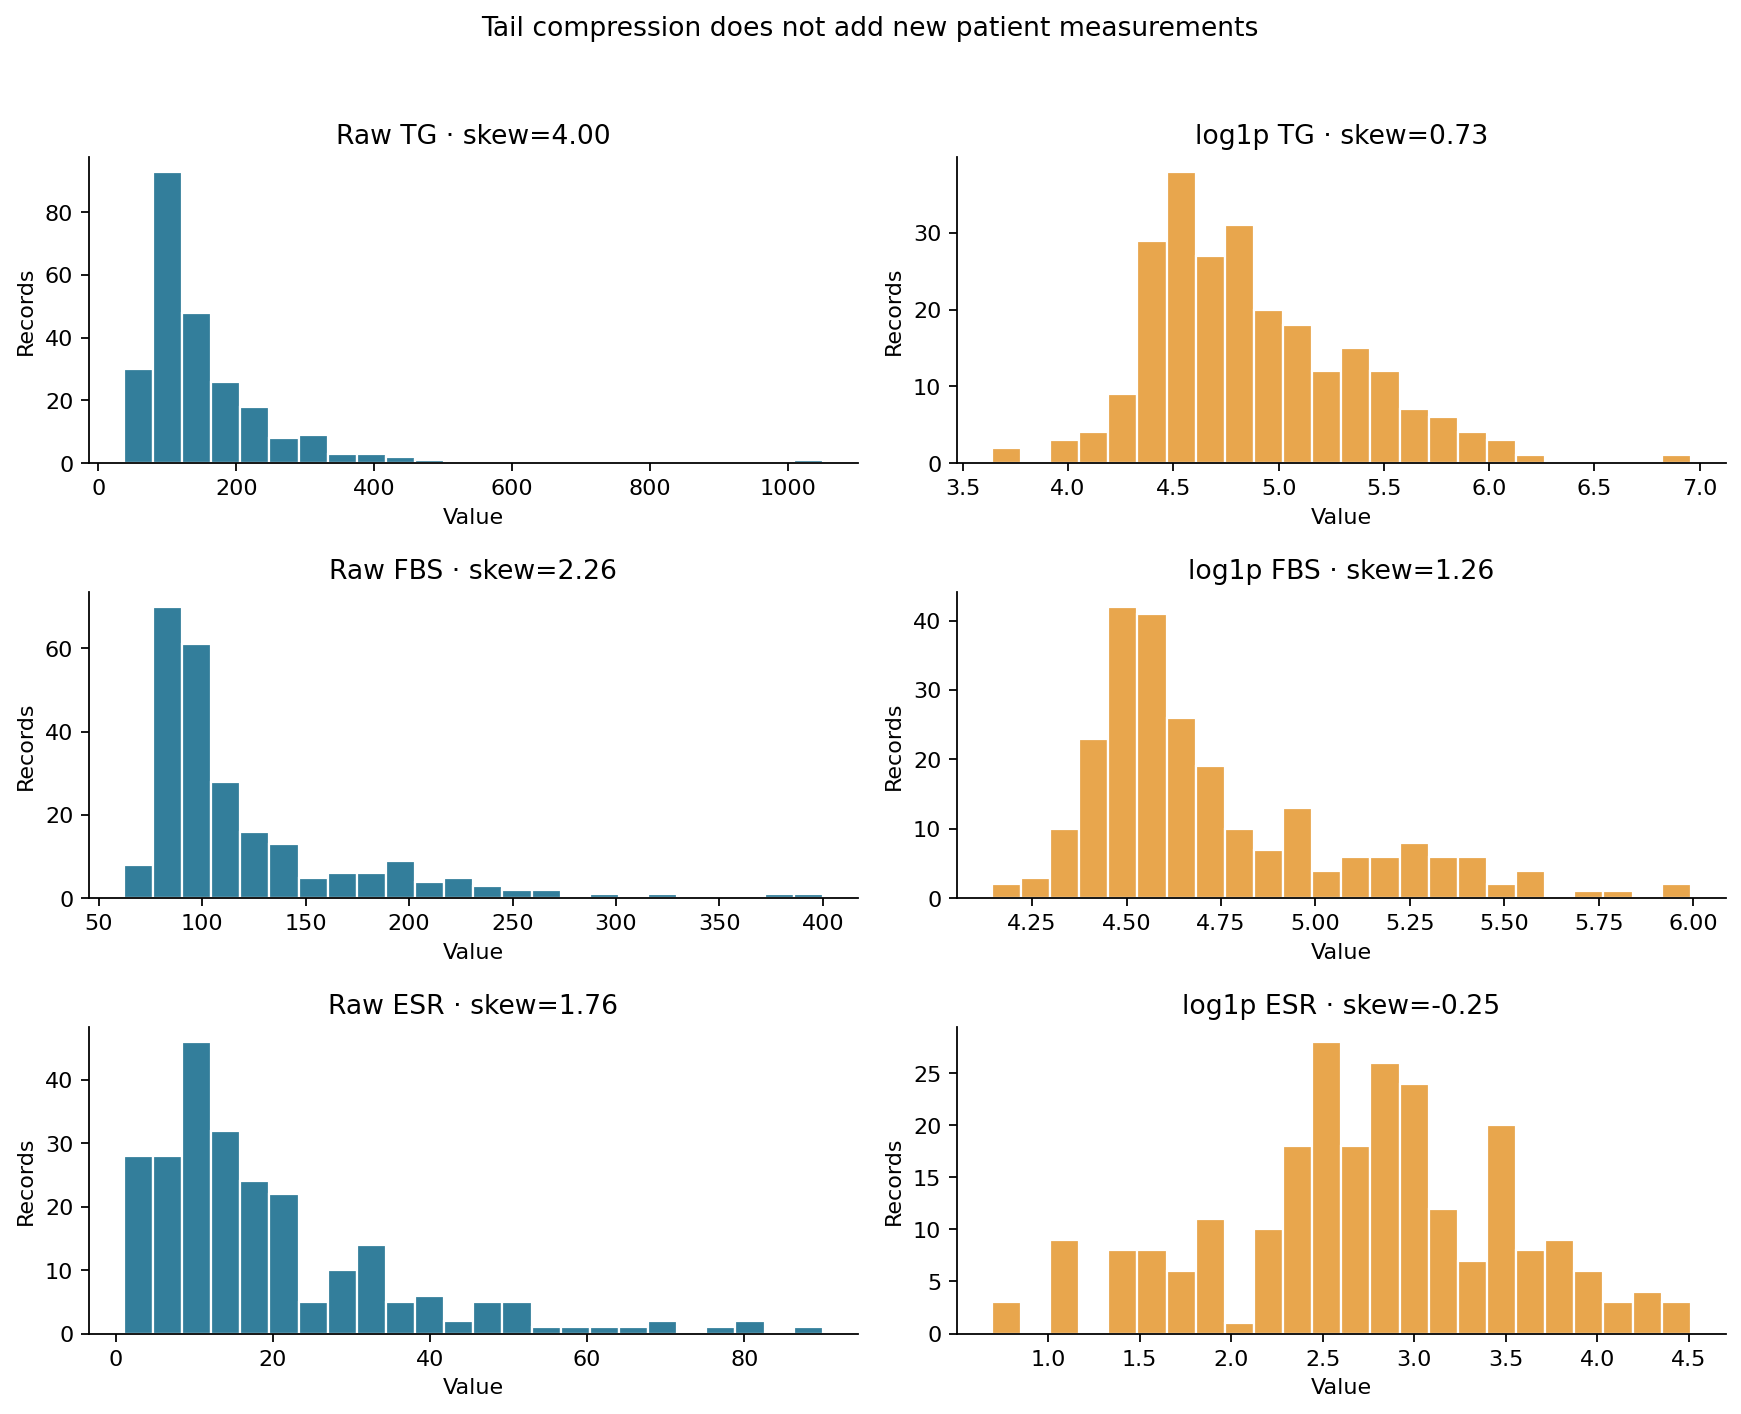

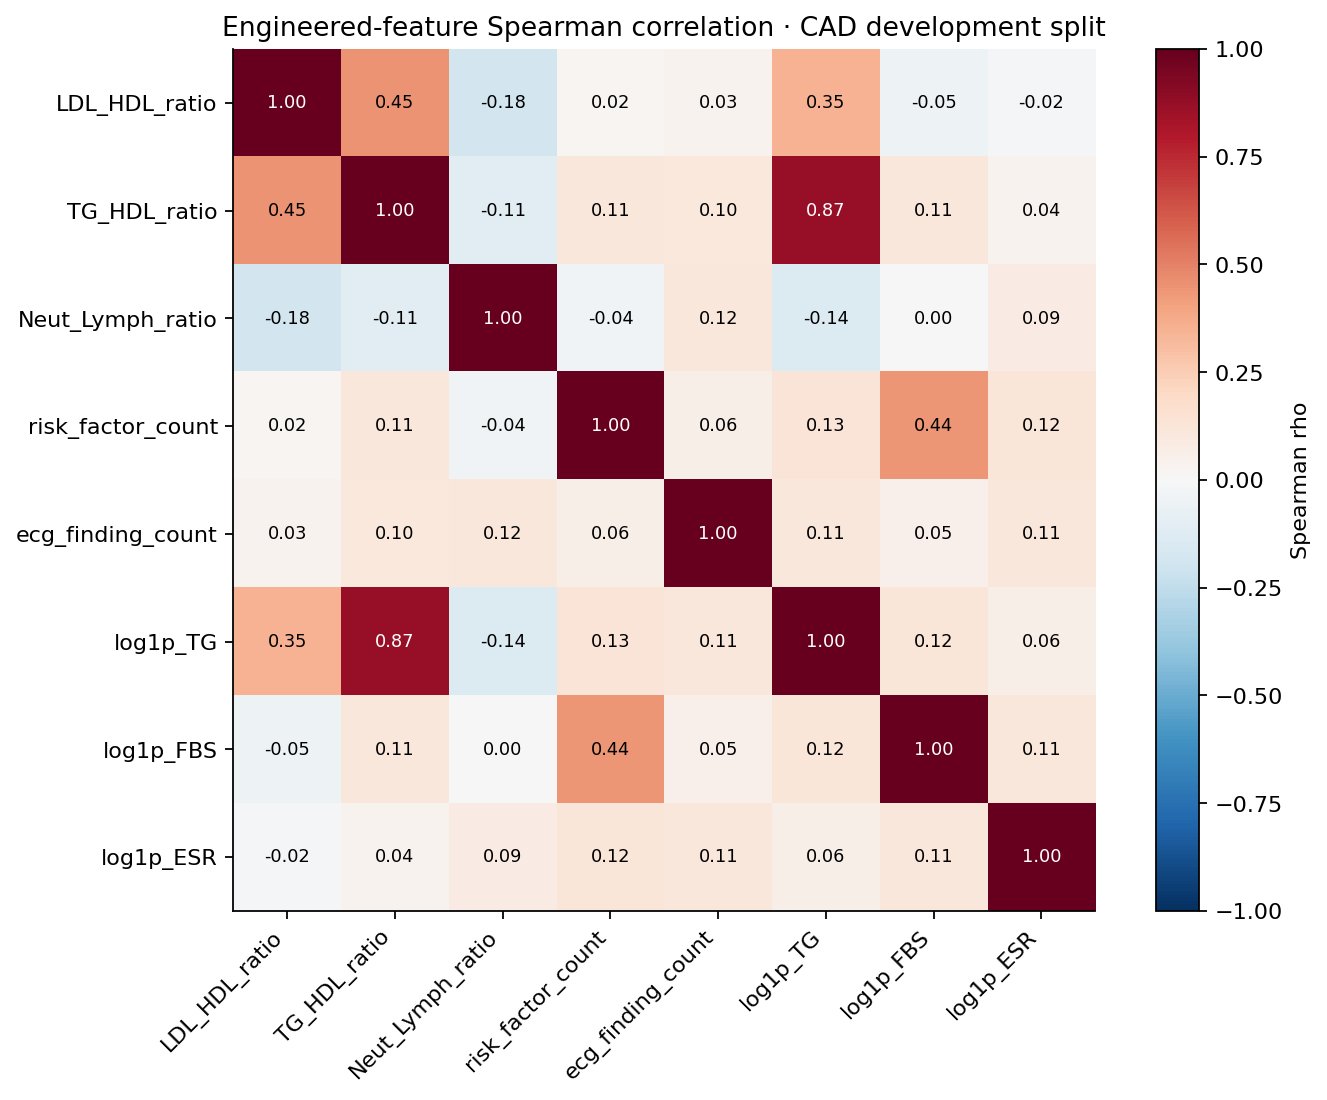

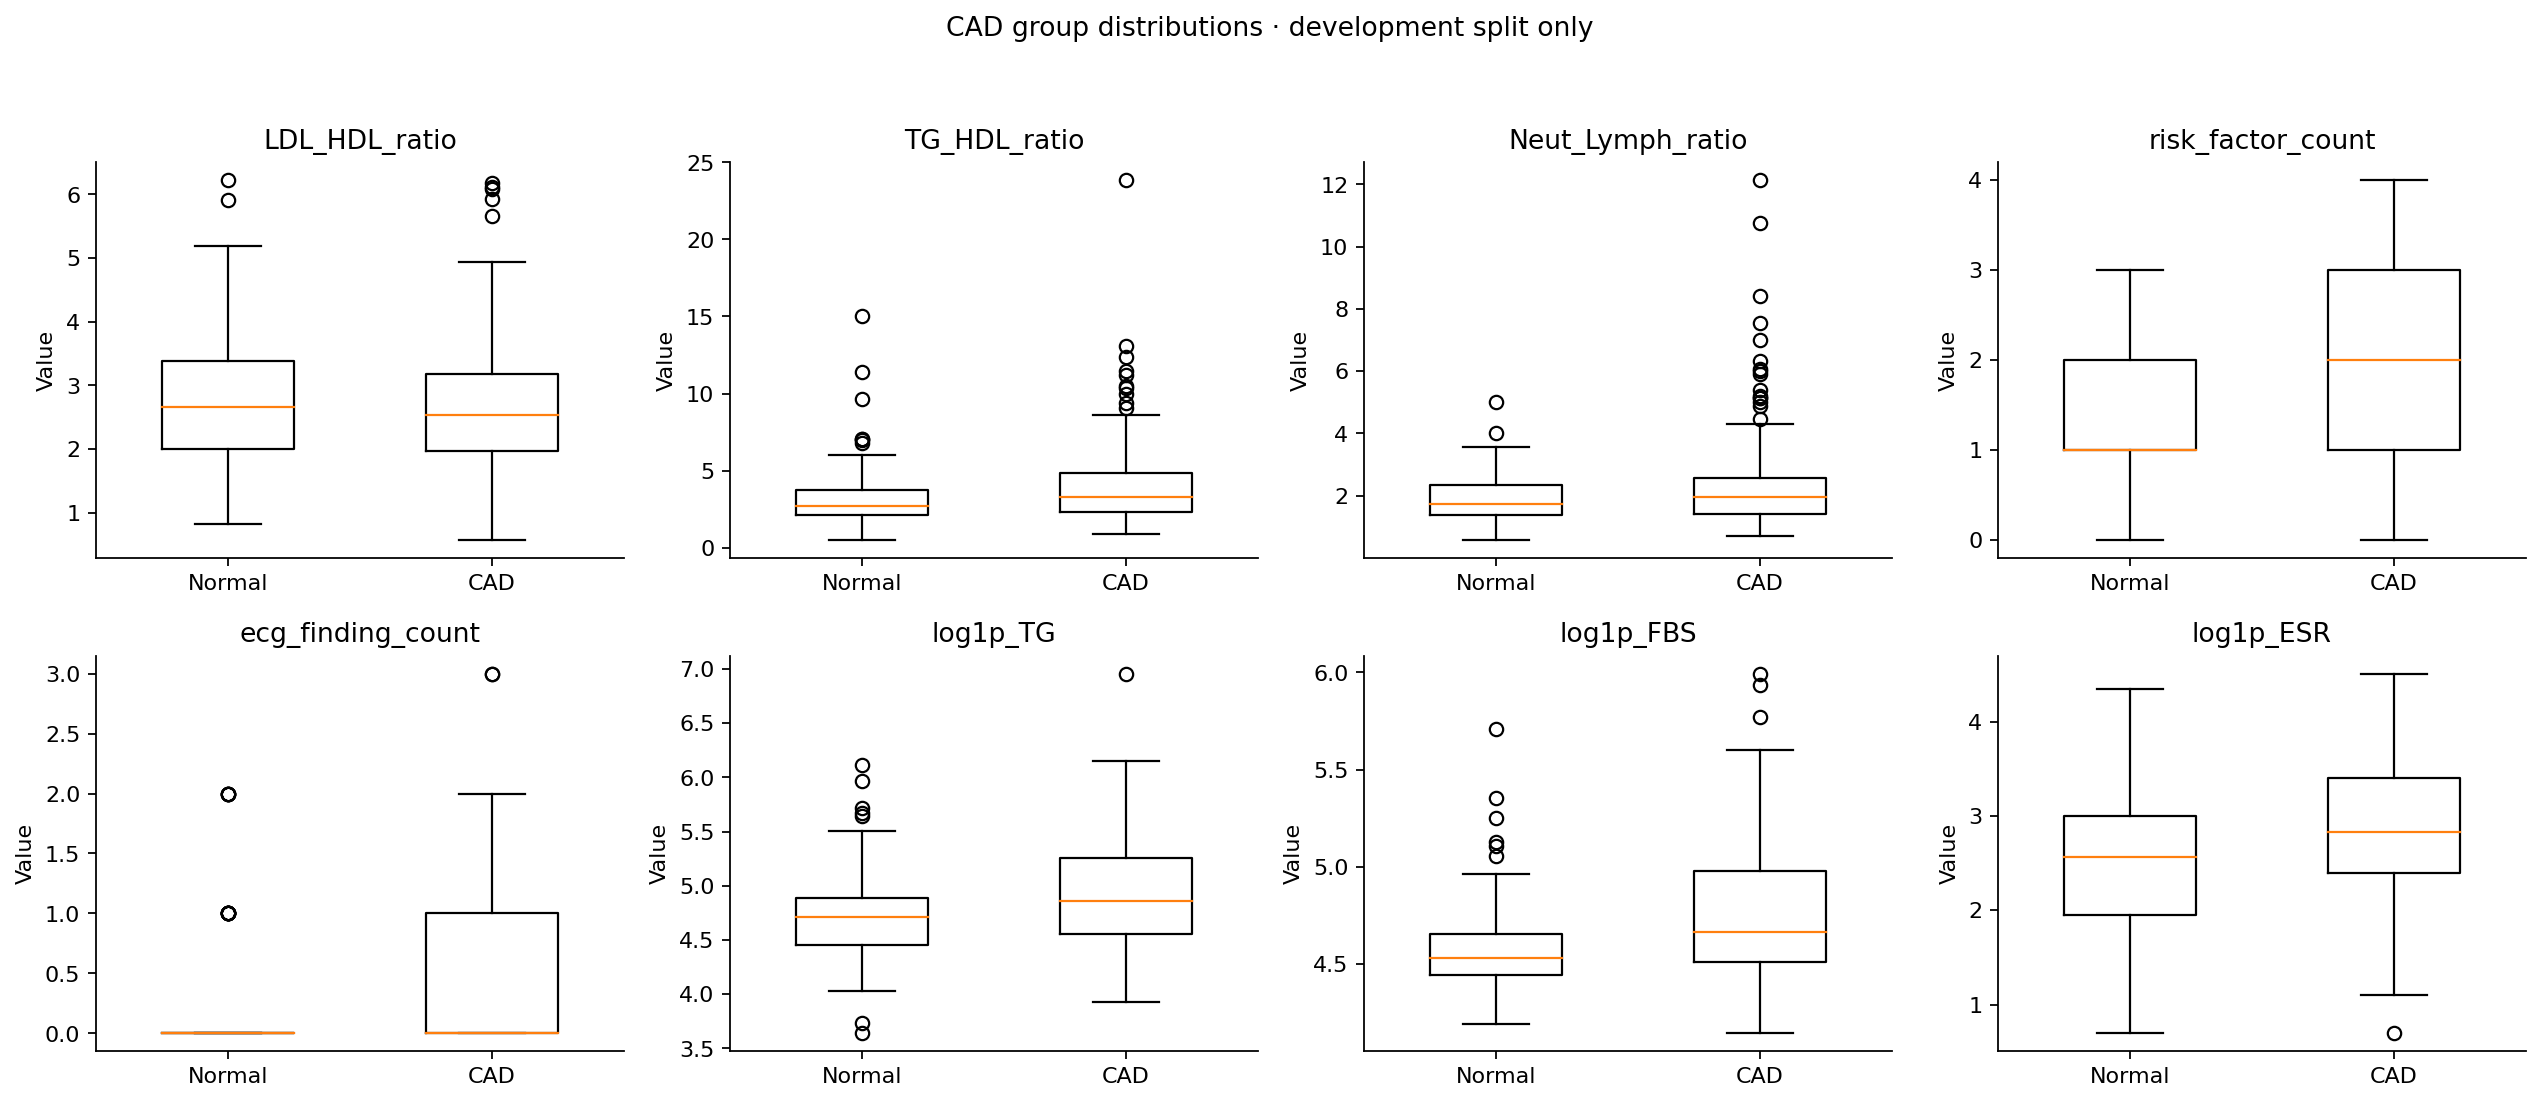

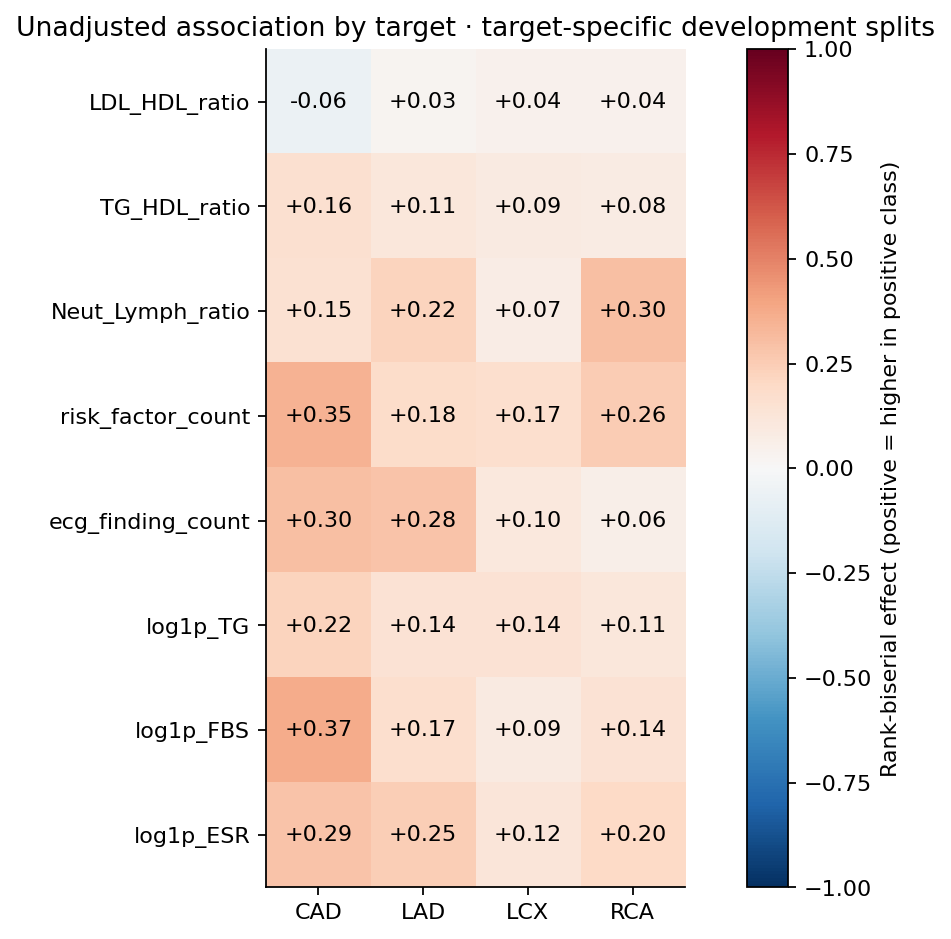

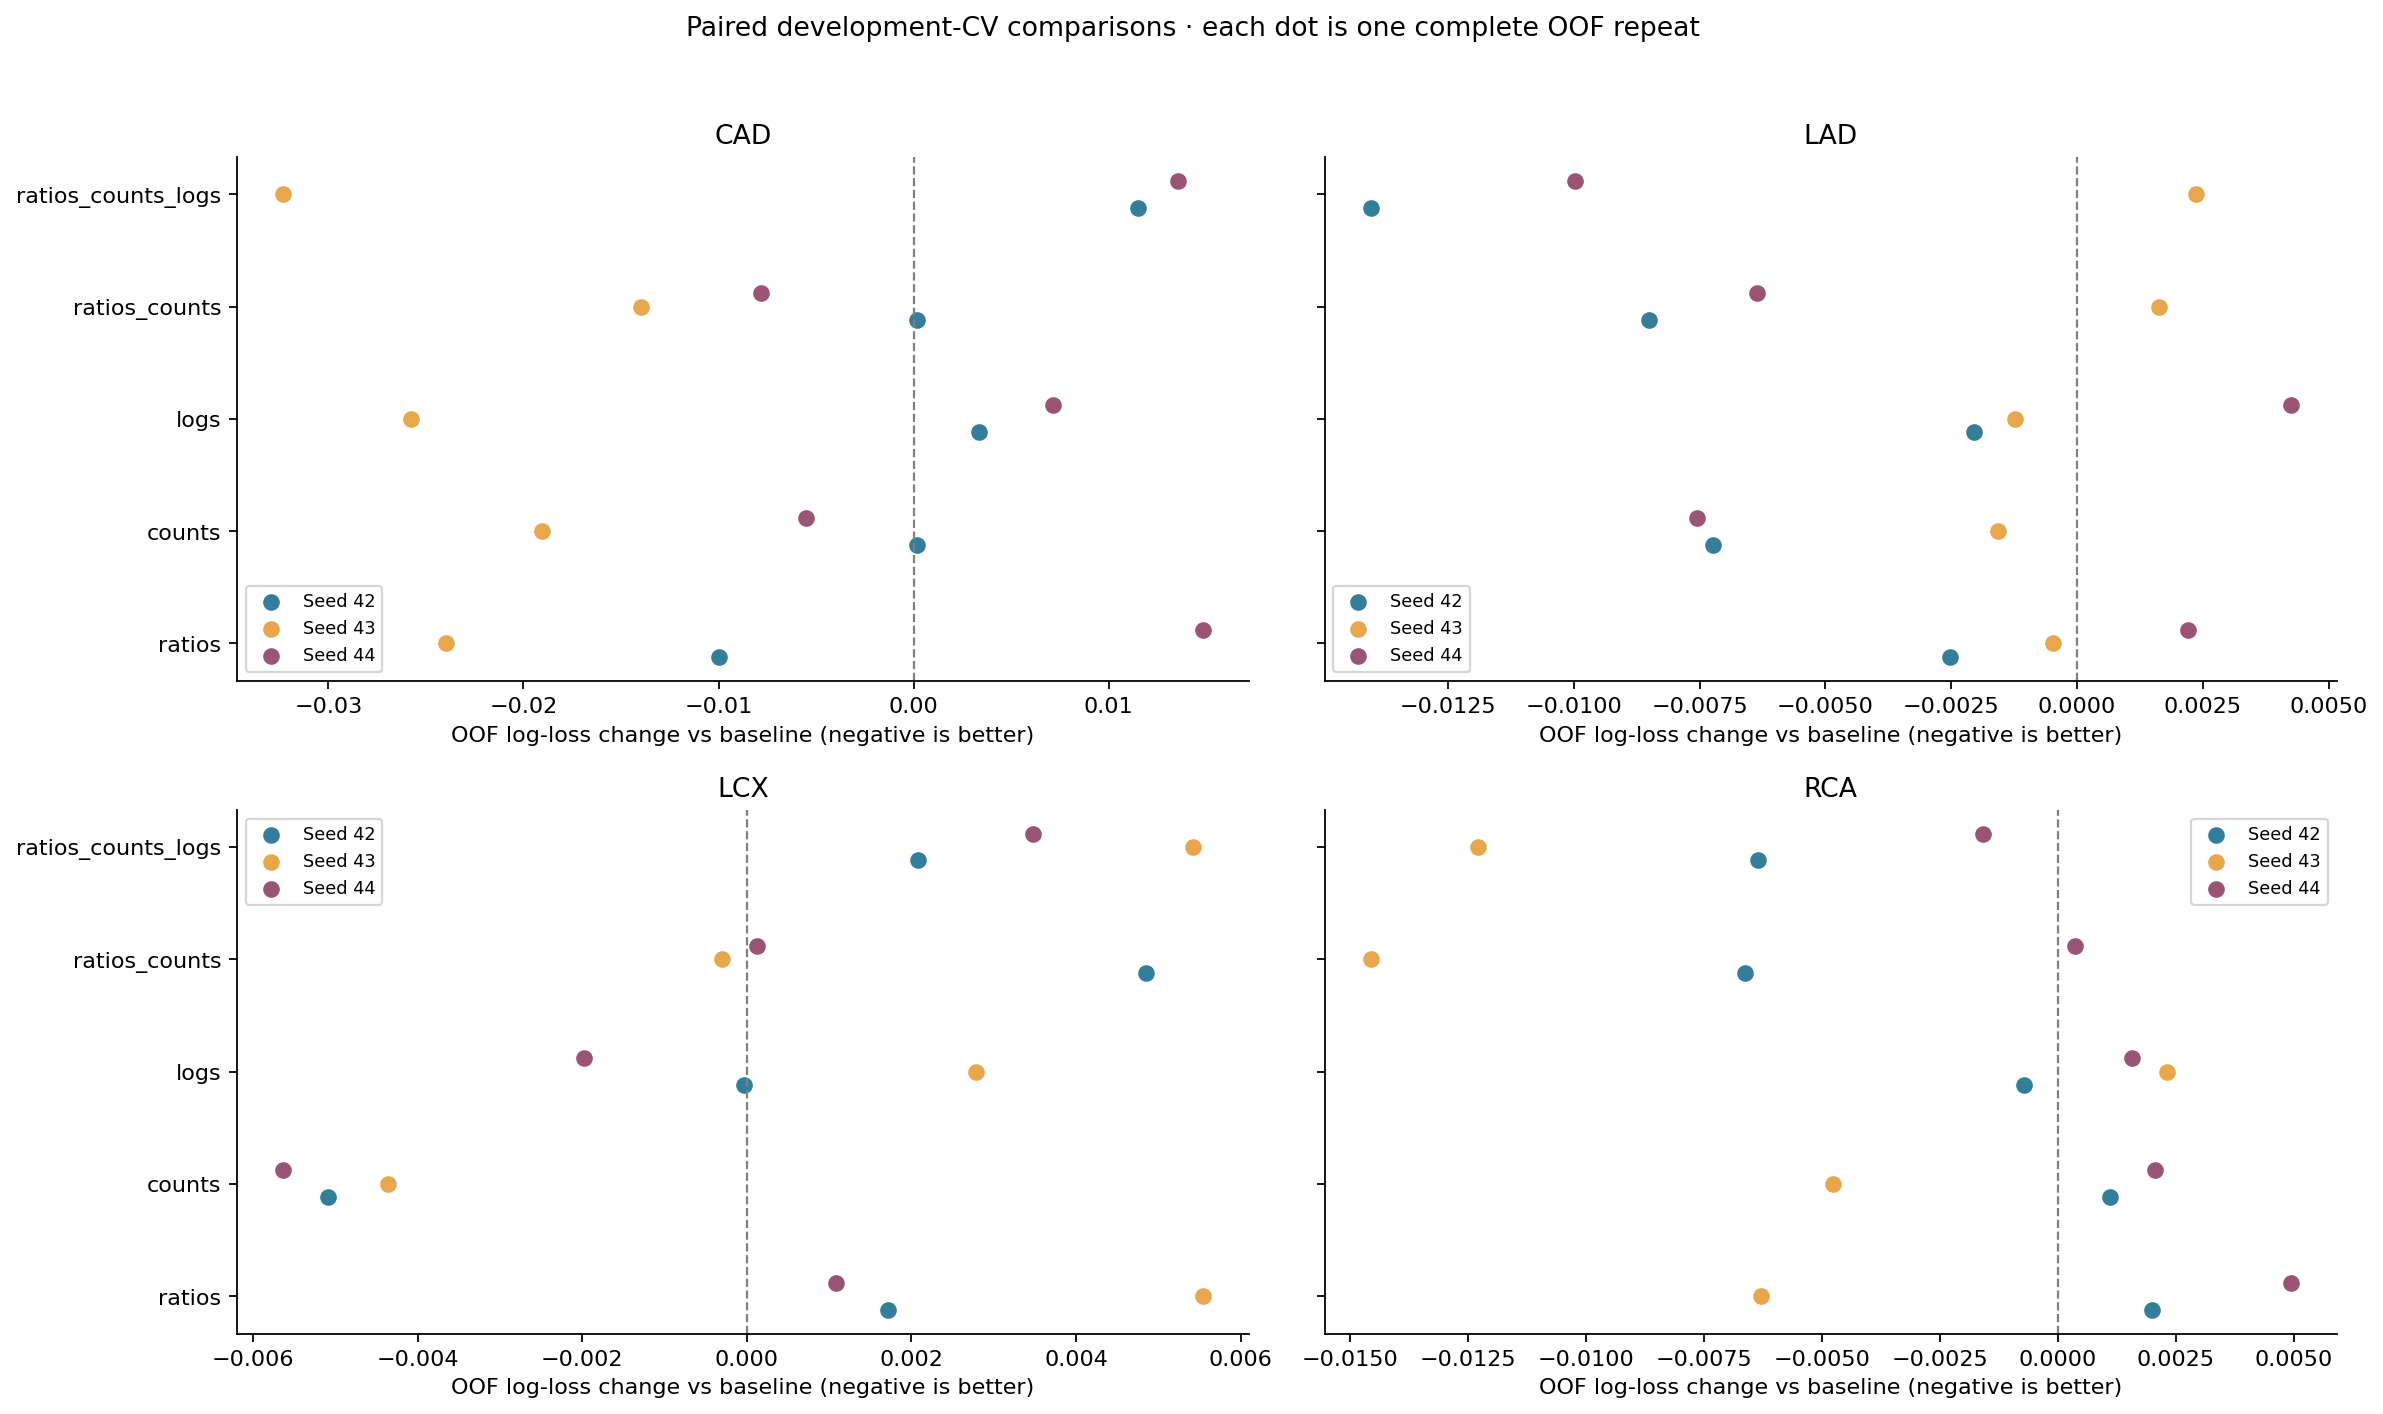

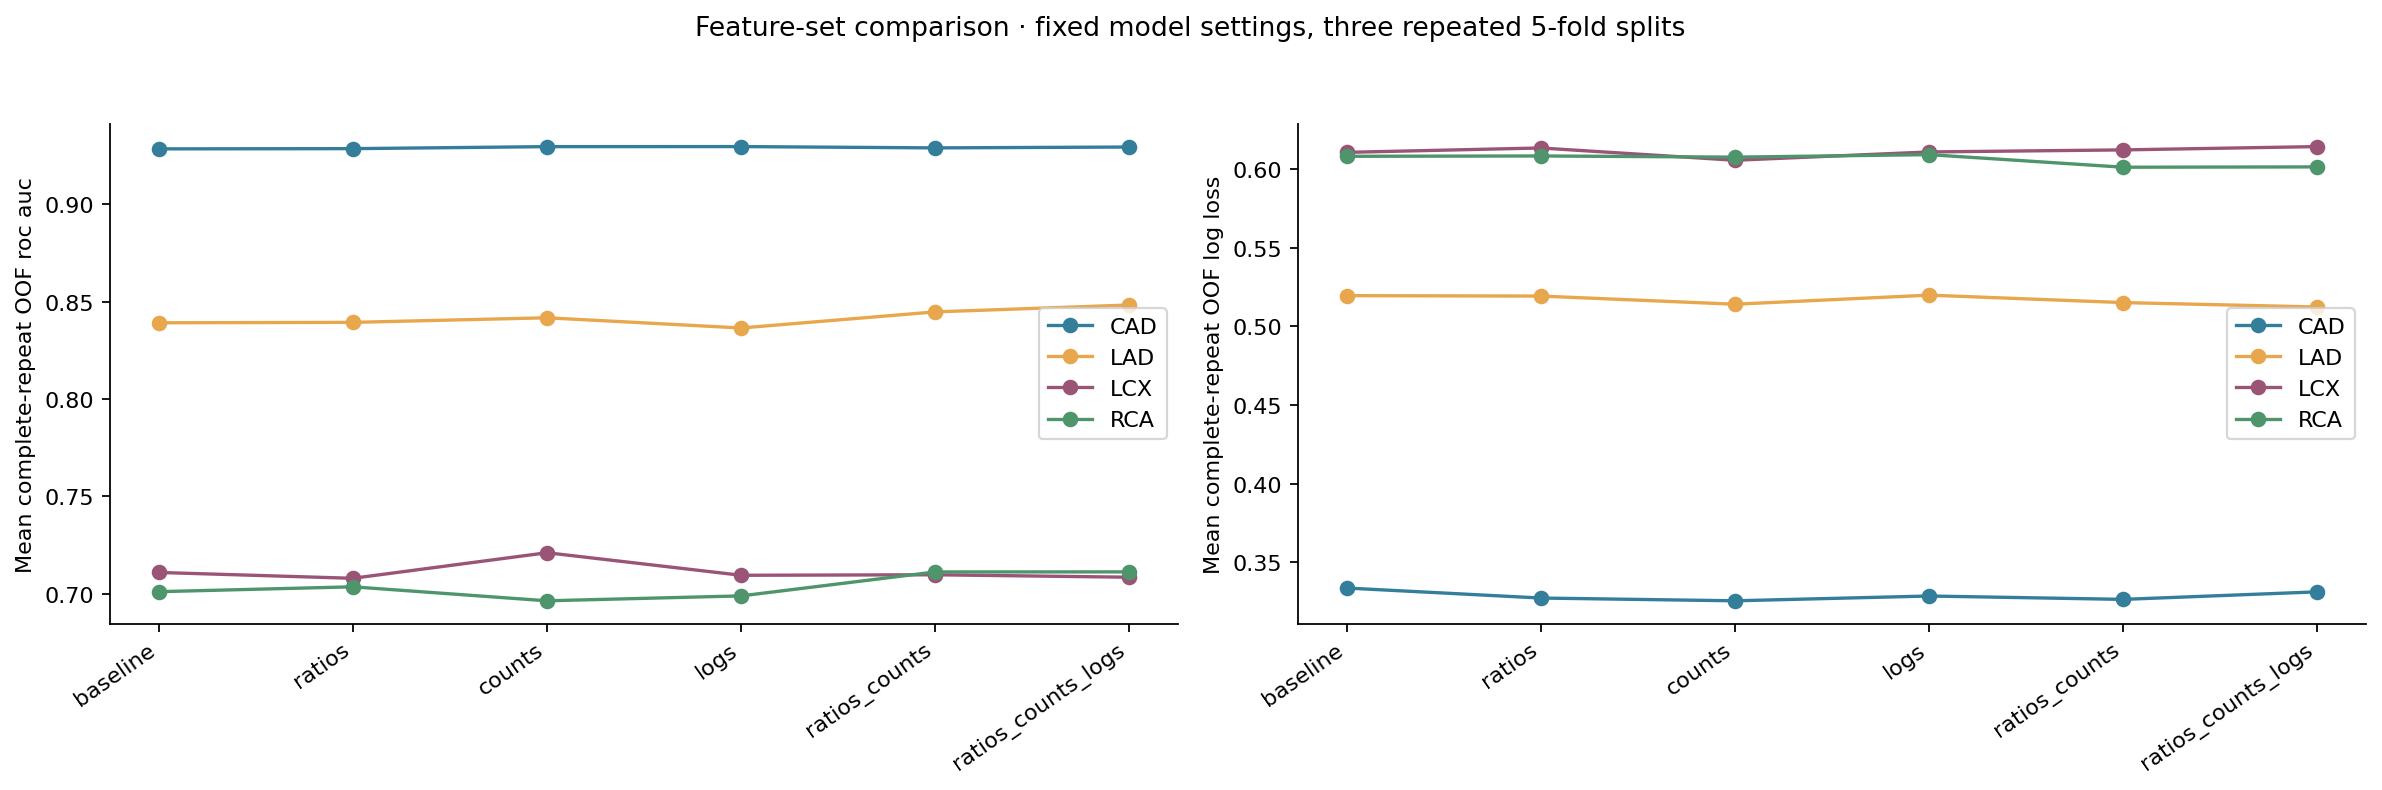

In [7]:
figures = fe.make_figures(df, partitions, raw, derived, correlations,
                          associations, cv_summary, paired_deltas)
for path in figures:
    display(Image(filename=str(path)))

## 7. Findings from this run

The following narrative is calculated from the executed tables. Lowest observed
loss is a descriptive ranking of these alternatives, not a validated deployment
choice. Compare the size and consistency of each change with the baseline before
designing the next nested experiment.

In [8]:
lines = []
for source in fe.LOG_SOURCES:
    lines.append(f"- **{source}:** skew changes from {skew.loc[source, 'raw_skew']:.2f} "
                 f"to {skew.loc[source, 'log_skew']:.2f} after log1p.")
cad_assoc = associations[associations.target.eq("cad")].copy()
cad_assoc["effect_magnitude"] = cad_assoc.rank_biserial.abs()
strongest = cad_assoc.sort_values("effect_magnitude", ascending=False).iloc[0]
lines.append(f"- **Largest observed CAD association among the eight candidates:** "
             f"{strongest.feature}, feature AUC {strongest.feature_auc:.3f}, "
             f"rank-biserial effect {strongest.rank_biserial:+.3f}, "
             f"BH-adjusted p {strongest.q_value_bh_32_tests:.4g}. "
             "This is a marginal association, not incremental model performance.")
for target in fe.TARGETS:
    block = cv_summary[cv_summary.target.eq(target)]
    baseline = block[block.variant.eq("baseline")].iloc[0]
    best = block.sort_values("log_loss_mean").iloc[0]
    if best.variant == "baseline":
        lines.append(f"- **{target.upper()}:** the original inputs have the lowest mean "
                     f"OOF log loss ({baseline.log_loss_mean:.4f}); none of the tested "
                     "feature sets improves that mean.")
    else:
        paired = paired_deltas[(paired_deltas.target.eq(target)) &
                                (paired_deltas.variant.eq(best.variant))]
        improved = int(paired.delta_log_loss.lt(0).sum())
        lines.append(f"- **{target.upper()}:** `{best.variant}` has the lowest observed "
                     f"mean OOF log loss: {baseline.log_loss_mean:.4f} → {best.log_loss_mean:.4f} "
                     f"(change {best.log_loss_mean - baseline.log_loss_mean:+.4f}); "
                     f"AUC changes {baseline.roc_auc_mean:.4f} → {best.roc_auc_mean:.4f}. "
                     f"Log loss improves in {improved}/3 paired repeats.")
lines.extend([
    "- Ratios/counts summarize existing measurements; they do not create independent "
    "clinical information. Log transforms preserve ranks exactly.",
    "- Feature choices can differ by target and metric. A small observed improvement "
    "in this exploratory analysis is not evidence of a robust generalization gain.",
    "- Before adopting a feature set, include the baseline and these candidates in "
    "inner-fold selection, then evaluate the complete selection procedure on outer "
    "folds. Revisit individual features only in that training-side procedure.",
])
findings = chr(10).join(lines)
display(Markdown(findings))
(fe.OUTPUT / "findings.txt").write_text(findings + chr(10))

Out[1]: 1598


- **TG:** skew changes from 4.00 to 0.73 after log1p.
- **FBS:** skew changes from 2.26 to 1.26 after log1p.
- **ESR:** skew changes from 1.76 to -0.25 after log1p.
- **Largest observed CAD association among the eight candidates:** log1p_FBS, feature AUC 0.685, rank-biserial effect +0.371, BH-adjusted p 0.0001731. This is a marginal association, not incremental model performance.
- **CAD:** `counts` has the lowest observed mean OOF log loss: 0.3337 → 0.3256 (change -0.0081); AUC changes 0.9284 → 0.9296. Log loss improves in 2/3 paired repeats.
- **LAD:** `ratios_counts_logs` has the lowest observed mean OOF log loss: 0.5196 → 0.5124 (change -0.0072); AUC changes 0.8391 → 0.8483. Log loss improves in 2/3 paired repeats.
- **LCX:** `counts` has the lowest observed mean OOF log loss: 0.6107 → 0.6056 (change -0.0050); AUC changes 0.7110 → 0.7211. Log loss improves in 3/3 paired repeats.
- **RCA:** `ratios_counts` has the lowest observed mean OOF log loss: 0.6082 → 0.6012 (change -0.0069); AUC changes 0.7011 → 0.7113. Log loss improves in 2/3 paired repeats.
- Ratios/counts summarize existing measurements; they do not create independent clinical information. Log transforms preserve ranks exactly.
- Feature choices can differ by target and metric. A small observed improvement in this exploratory analysis is not evidence of a robust generalization gain.
- Before adopting a feature set, include the baseline and these candidates in inner-fold selection, then evaluate the complete selection procedure on outer folds. Revisit individual features only in that training-side procedure.

## 8. Reproducibility and artifacts

Run this notebook from the repository root or `dataset/`, using the dependencies
in `training/requirements.txt` plus Jupyter/IPython. Rerunning overwrites only the
analysis outputs in `dataset/engineered_feature_analysis/`.

```bash
MPLCONFIGDIR=/tmp/cardisoft-feature-mpl OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 \
python3 -m nbconvert --to notebook --execute --inplace \
  dataset/engineered-feature-analysis.ipynb --ExecutePreprocessor.timeout=1800
```

Key outputs:
- `engineered_features.csv`: eight deterministic derived features for all 303 rows,
  joined to the source by zero-based `row_index`; no labels or selected features.
- `feature_definitions.csv`, `feature_summary.csv`, `log_transform_skew.csv`,
  `strongest_raw_correlations.csv`, `spearman_correlations.csv` and count tables.
- `target_associations.csv`: group medians/IQRs, rank effects and exploratory tests.
- `partitions.csv`, `cv_splits.json`: exact data partitions and CV fold memberships.
- `cv_fold_metrics.csv`, `cv_oof_predictions.csv`, `cv_repeat_metrics.csv`,
  `cv_summary.csv`, `cv_paired_deltas.csv`, `cv_paired_summary.csv`: audit trail
  from individual predictions to reported comparisons.
- Seven PNG figures, `findings.txt` and `provenance.json`.

An analysis-only transformer implements these candidates here. If adopted later,
move the accepted definitions into shared production preprocessing and verify
training/inference parity before retraining and exporting models.

In [9]:
display(pd.Series(provenance["packages"], name="installed_version").to_frame())
print("Dataset SHA-256:", provenance["dataset_sha256"])
print("Analysis outputs:", fe.OUTPUT)
display(pd.DataFrame([{"file": p.name, "size_KiB": round(p.stat().st_size / 1024, 1)}
                      for p in sorted(fe.OUTPUT.iterdir()) if p.is_file()]))

Dataset SHA-256: dfe06e123151f995437c60a77f8bfa9ddf68848958b2ea2b7a6eb60c42971af0
Analysis outputs: /home/remandey/my-programs/Cardisoft/dataset/engineered_feature_analysis


,installed_version
numpy,1.26.4
pandas,2.2.3
scipy,1.14.1
scikit-learn,1.7.2
catboost,1.2.10
matplotlib,3.7.5


,file,size_KiB
0,cad_group_distributions.png,114.0
1,count_frequencies.csv,0.2
2,cv_feature_set_comparison.png,111.9
3,cv_fold_metrics.csv,45.0
4,cv_log_loss_deltas.png,129.1
5,cv_oof_predictions.csv,749.2
6,cv_paired_deltas.csv,25.2
7,cv_paired_summary.csv,4.0
8,cv_repeat_metrics.csv,9.3
9,cv_splits.json,157.7
